# Phase 3: EDA

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. Apply clean Seaborn styling across all figures
sns.set_theme(style='whitegrid')

# 2. Ensure destination folder exists
os.makedirs('figures', exist_ok=True)

# 3. Load the cleaned master dataset
df = pd.read_csv('cleaned_master.csv')
df['week_start'] = pd.to_datetime(df['week_start'])

print(f"Loaded master dataset: {df.shape[0]:,} rows and {df.shape[1]} columns.")

Loaded master dataset: 46,800 rows and 47 columns.


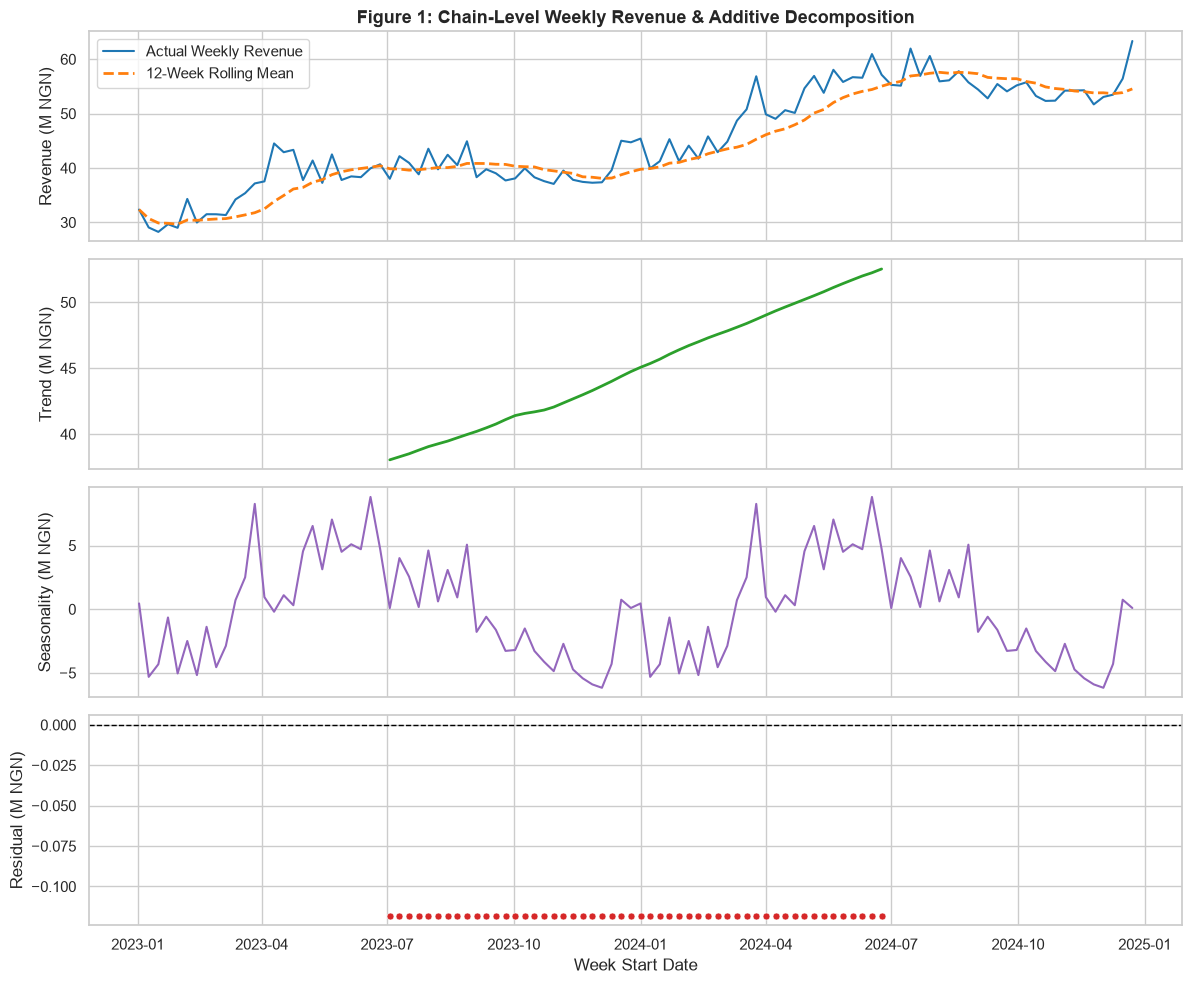

Figure 1 saved to figures/fig1_revenue_ts.png (300 DPI)


In [2]:
# -------------------------------------------------------------------------
# Figure 1: Chain-Level Weekly Revenue & Additive Decomposition
# -------------------------------------------------------------------------

# 1. Aggregate revenue at chain level per week (scaled to Millions of NGN)
weekly_rev = df.groupby('week_start')['revenue_ngn'].sum().reset_index()
weekly_rev['revenue_m_ngn'] = weekly_rev['revenue_ngn'] / 1e6
weekly_rev['rolling_12'] = weekly_rev['revenue_m_ngn'].rolling(window=12, min_periods=1).mean()

# 2. Decompose weekly revenue into trend, seasonality (52 weeks), and residual
decomp = seasonal_decompose(weekly_rev.set_index('week_start')['revenue_m_ngn'], model='additive', period=52)

# Build a tidy DataFrame for Seaborn
decomp_df = pd.DataFrame({
    'week_start': weekly_rev['week_start'],
    'Actual Revenue': weekly_rev['revenue_m_ngn'],
    '12-Week Rolling Mean': weekly_rev['rolling_12'],
    'Trend': decomp.trend.values,
    'Seasonality': decomp.seasonal.values,
    'Residual': decomp.resid.values
})

# 3. Plot 4 stacked subplots using Seaborn
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

# Panel 1: Observed Weekly Revenue and 12-Week Moving Average
sns.lineplot(data=weekly_rev, x='week_start', y='revenue_m_ngn', ax=axes[0], label='Actual Weekly Revenue', color='#1f77b4', lw=1.5)
sns.lineplot(data=weekly_rev, x='week_start', y='rolling_12', ax=axes[0], label='12-Week Rolling Mean', color='#ff7f0e', lw=2, linestyle='--')
axes[0].set_ylabel('Revenue (M NGN)')
axes[0].set_title('Figure 1: Chain-Level Weekly Revenue & Additive Decomposition', fontsize=13, fontweight='bold')
axes[0].legend(loc='upper left')

# Panel 2: Trend Component
sns.lineplot(data=decomp_df, x='week_start', y='Trend', ax=axes[1], color='#2ca02c', lw=2)
axes[1].set_ylabel('Trend (M NGN)')

# Panel 3: Seasonal Component
sns.lineplot(data=decomp_df, x='week_start', y='Seasonality', ax=axes[2], color='#9467bd', lw=1.5)
axes[2].set_ylabel('Seasonality (M NGN)')

# Panel 4: Residual Component
sns.scatterplot(data=decomp_df, x='week_start', y='Residual', ax=axes[3], color='#d62728', s=25)
axes[3].axhline(0, color='black', linestyle='--', linewidth=1)
axes[3].set_ylabel('Residual (M NGN)')
axes[3].set_xlabel('Week Start Date')

plt.tight_layout()

# 4. Save directly as 300 DPI PNG
plt.savefig('figures/fig1_revenue_ts.png', dpi=300)
plt.show()

print("Figure 1 saved to figures/fig1_revenue_ts.png (300 DPI)")

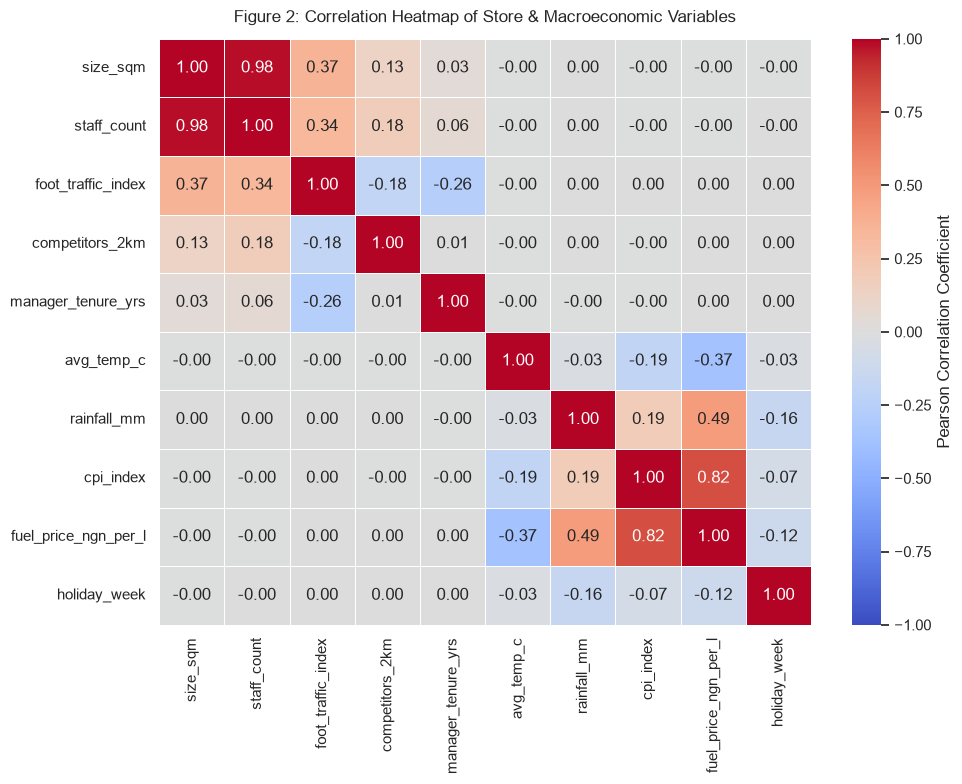

Figure 2 saved to figures/fig2_correlation_heatmap.png


In [3]:
# -------------------------------------------------------------------------
# Figure 2: Correlation Heatmap (Numeric Store & Macro Variables)
# -------------------------------------------------------------------------

# 1. Define the store-level and external macro variables
store_macro_vars = [
    'size_sqm', 'staff_count', 'foot_traffic_index', 'competitors_2km', 
    'manager_tenure_yrs', 'avg_temp_c', 'rainfall_mm', 'cpi_index', 
    'fuel_price_ngn_per_l', 'holiday_week'
]

# 2. Compute Pearson correlation matrix
corr_matrix = df[store_macro_vars].corr()

# 3. Create the heatmap using Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    center=0,
    linewidths=0.5, 
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title('Figure 2: Correlation Heatmap of Store & Macroeconomic Variables', fontsize=12, pad=12)
plt.tight_layout()

# 4. Save at 300 DPI
plt.savefig('figures/fig2_correlation_heatmap.png', dpi=300)
plt.show()

print("Figure 2 saved to figures/fig2_correlation_heatmap.png")

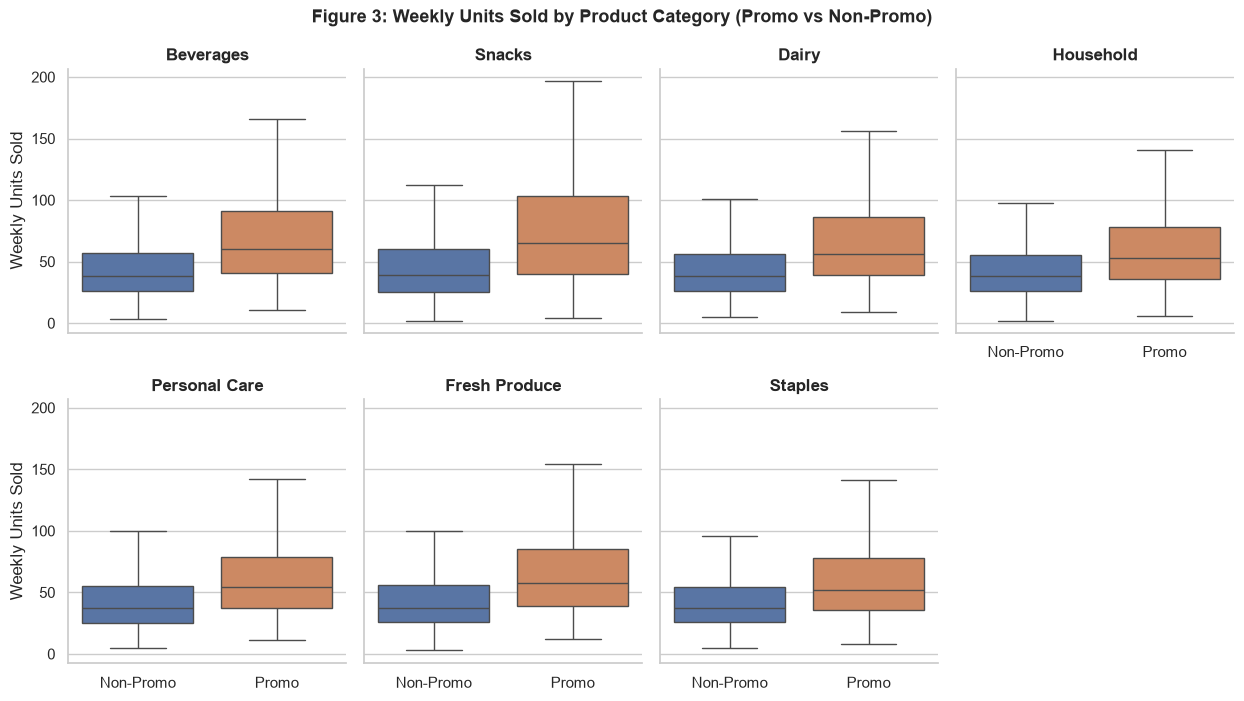

Figure 3 saved cleanly to figures/fig3_promo_by_category.png


In [5]:
# -------------------------------------------------------------------------
# Figure 3: Promo vs Non-Promo Units Sold by Category (Faceted)
# -------------------------------------------------------------------------

# 1. Create readable labels for promotional status
df['promo_label'] = df['promo_flag'].map({0: 'Non-Promo', 1: 'Promo'})

# 2. Build faceted boxplot across all 7 product categories
g = sns.catplot(
    data=df,
    x='promo_label',
    y='units_sold',
    hue='promo_label',       # Explicitly maps color palette to the x variable
    col='category',
    col_wrap=4,
    kind='box',
    showfliers=False,        # Suppresses outlier dots for clean interquartile comparison
    palette=['#4c72b0', '#dd8452'],
    legend=False,            # Suppresses redundant legend
    height=3.5,
    aspect=0.9,
    sharey=True
)

# 3. Apply titles and labels
g.set_axis_labels('', 'Weekly Units Sold')
g.set_titles(col_template='{col_name}', weight='bold')
g.fig.suptitle('Figure 3: Weekly Units Sold by Product Category (Promo vs Non-Promo)', fontsize=13, fontweight='bold', y=1.03)

# 4. Save figure directly at 300 DPI
g.savefig('figures/fig3_promo_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 3 saved cleanly to figures/fig3_promo_by_category.png")

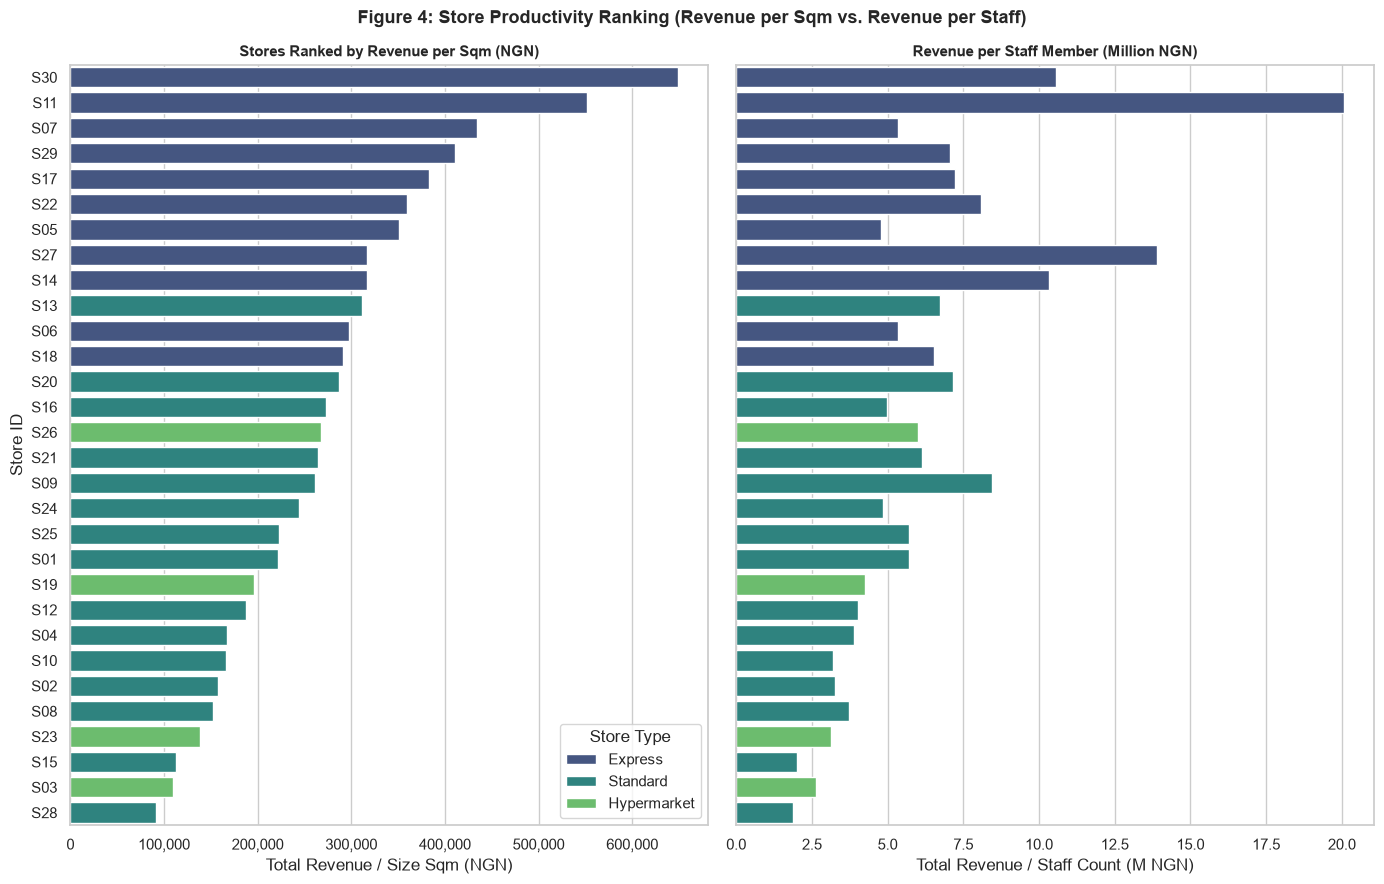

Figure 4 saved to figures/fig4_store_productivity.png


In [6]:
# -------------------------------------------------------------------------
# Figure 4: Store Productivity Ranking (Revenue / Sqm vs. Revenue / Staff)
# -------------------------------------------------------------------------

# 1. Aggregate total revenue per store and calculate efficiency metrics
store_perf = df.groupby(['store_id', 'store_type', 'size_sqm', 'staff_count'])['revenue_ngn'].sum().reset_index()
store_perf['rev_per_sqm'] = store_perf['revenue_ngn'] / store_perf['size_sqm']
store_perf['rev_per_staff_m'] = (store_perf['revenue_ngn'] / store_perf['staff_count']) / 1e6

# 2. Sort descending by revenue per square metre
store_perf = store_perf.sort_values('rev_per_sqm', ascending=False).reset_index(drop=True)

# 3. Create side-by-side comparative horizontal barplots
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharey=True)

# Left Panel: Store Ranking by Revenue per Sqm
sns.barplot(
    data=store_perf,
    y='store_id',
    x='rev_per_sqm',
    hue='store_type',
    dodge=False,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Stores Ranked by Revenue per Sqm (NGN)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Total Revenue / Size Sqm (NGN)')
axes[0].set_ylabel('Store ID')
axes[0].xaxis.set_major_formatter('{x:,.0f}')
axes[0].legend(title='Store Type', loc='lower right')

# Right Panel: Revenue per Staff Member (same store order)
sns.barplot(
    data=store_perf,
    y='store_id',
    x='rev_per_staff_m',
    hue='store_type',
    dodge=False,
    ax=axes[1],
    palette='viridis'
)
axes[1].set_title('Revenue per Staff Member (Million NGN)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Total Revenue / Staff Count (M NGN)')
axes[1].set_ylabel('')
axes[1].legend().remove()

plt.suptitle('Figure 4: Store Productivity Ranking (Revenue per Sqm vs. Revenue per Staff)', fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()

# 4. Save directly as 300 DPI PNG
plt.savefig('figures/fig4_store_productivity.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 4 saved to figures/fig4_store_productivity.png")

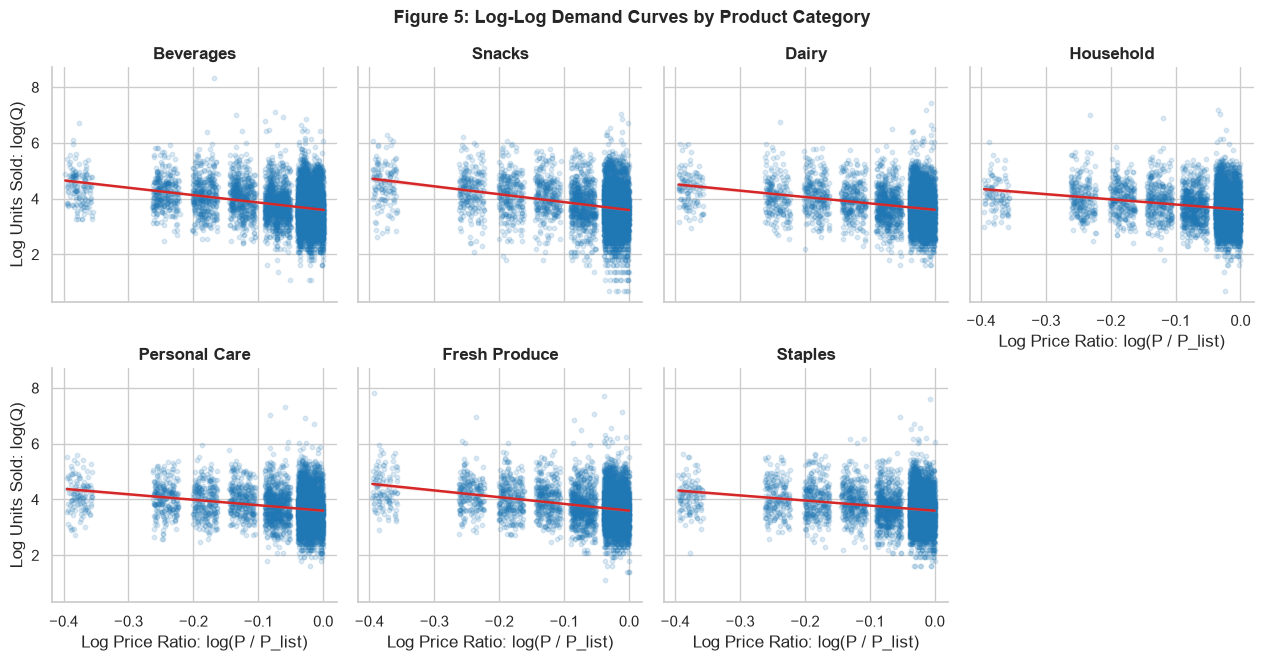

Figure 5 saved to figures/fig5_log_price_vs_log_units.png


In [7]:
# -------------------------------------------------------------------------
# Figure 5: Log-Log Demand Curves by Product Category (Faceted)
# -------------------------------------------------------------------------

# 1. Build faceted scatter plot with linear regression fit per category
g = sns.lmplot(
    data=df,
    x='log_price_ratio',
    y='log_units',
    col='category',
    col_wrap=4,
    height=3.2,
    aspect=1.0,
    scatter_kws={'alpha': 0.15, 's': 10, 'color': '#1f77b4'},
    line_kws={'color': '#d62728', 'linewidth': 1.8}
)

# 2. Add clear academic axis titles
g.set_axis_labels('Log Price Ratio: log(P / P_list)', 'Log Units Sold: log(Q)')
g.set_titles(col_template='{col_name}', weight='bold')
g.fig.suptitle('Figure 5: Log-Log Demand Curves by Product Category', fontsize=13, fontweight='bold', y=1.03)

# 3. Save figure at 300 DPI
g.savefig('figures/fig5_log_price_vs_log_units.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 5 saved to figures/fig5_log_price_vs_log_units.png")

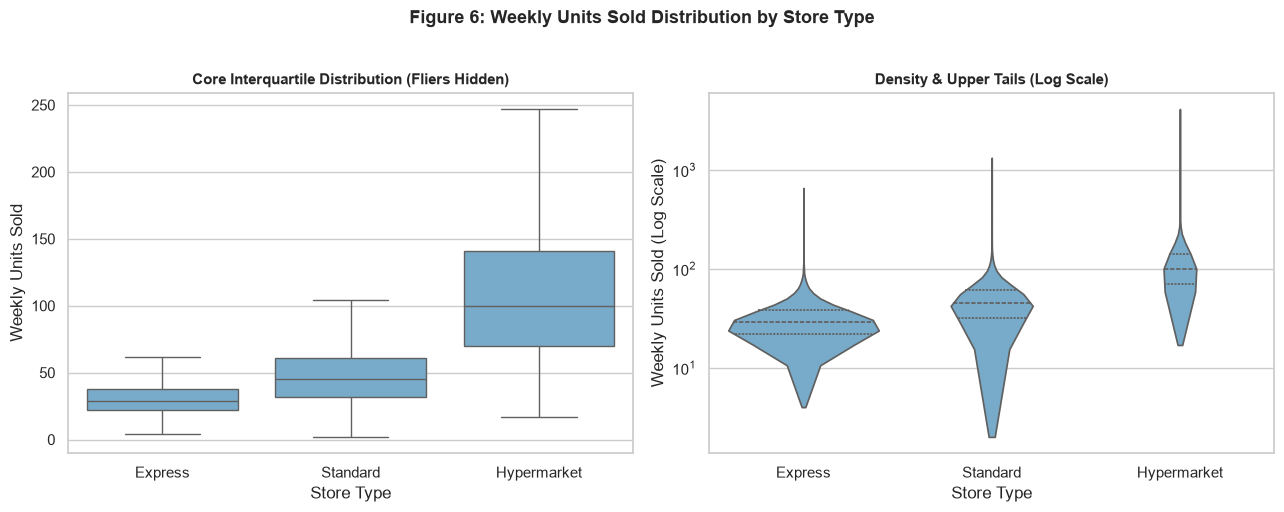

Figure 6 saved to figures/fig6_units_by_store_type.png


In [9]:
# -------------------------------------------------------------------------
# Figure 6: Distribution of Weekly Units Sold by Store Type
# -------------------------------------------------------------------------

# 1. Create a 2-panel comparative layout
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Order formats from smallest to largest
store_order = ['Express', 'Standard', 'Hypermarket']

# 2. Left Panel: Boxplot focusing on the interquartile range (IQR)
sns.boxplot(
    data=df, 
    x='store_type', 
    y='units_sold', 
    order=store_order,
    color='#6baed6',        # Single clean colour avoids palette/hue warnings
    showfliers=False,       # Suppresses extreme fliers for clear quartile comparison
    ax=axes[0]
)
axes[0].set_title('Core Interquartile Distribution (Fliers Hidden)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Store Type')
axes[0].set_ylabel('Weekly Units Sold')

# 3. Right Panel: Violin plot with log-scale to reveal density shapes & tails
sns.violinplot(
    data=df, 
    x='store_type', 
    y='units_sold', 
    order=store_order,
    color='#6baed6',
    cut=0,                  # Bounds density strictly within actual observed range
    inner='quartile',       # Draws dashed lines for 25th, 50th (median), and 75th percentiles
    ax=axes[1]
)
axes[1].set_yscale('log')
axes[1].set_title('Density & Upper Tails (Log Scale)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Store Type')
axes[1].set_ylabel('Weekly Units Sold (Log Scale)')

plt.suptitle('Figure 6: Weekly Units Sold Distribution by Store Type', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

# 4. Save figure at 300 DPI
plt.savefig('figures/fig6_units_by_store_type.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 6 saved to figures/fig6_units_by_store_type.png")

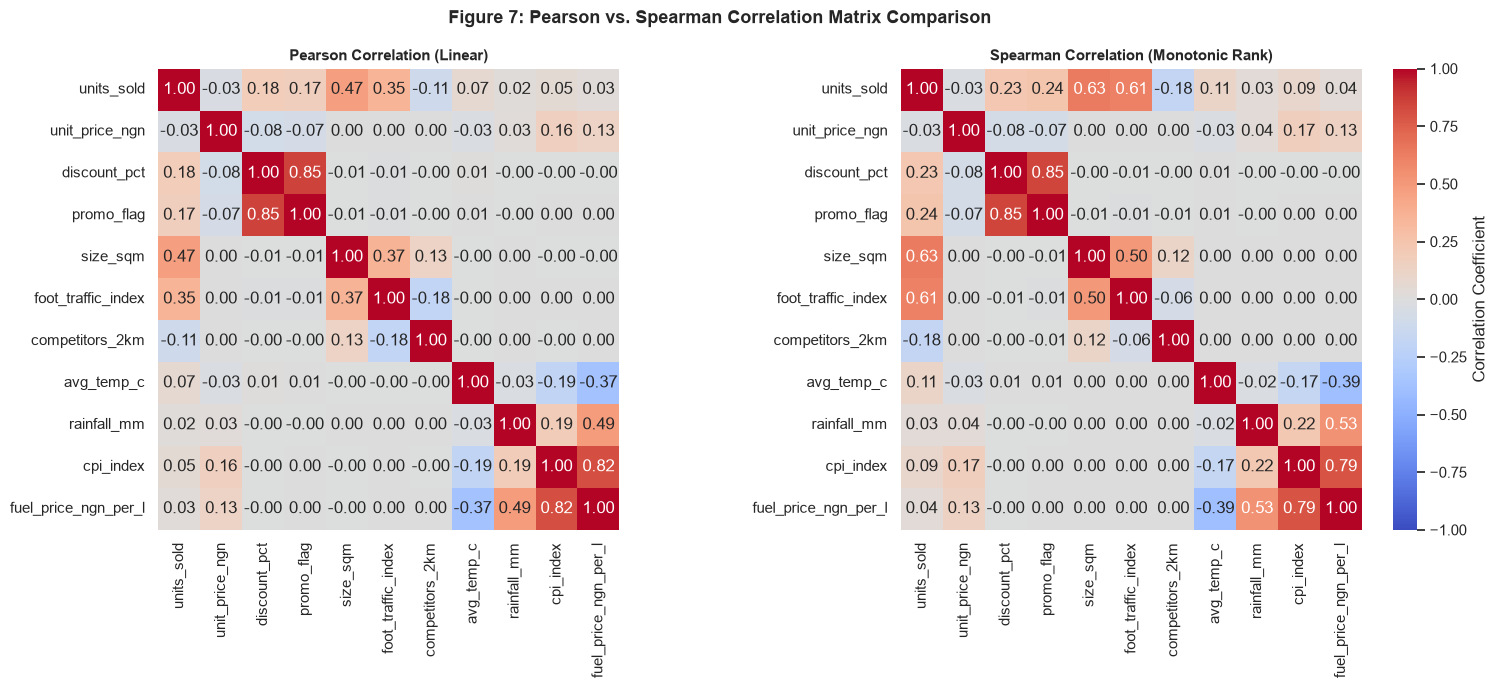


Top 5 Discrepancies (|Pearson - Spearman|):
foot_traffic_index vs units_sold: Pearson = 0.35, Spearman = 0.61 (Diff = 0.26)
size_sqm vs units_sold: Pearson = 0.47, Spearman = 0.63 (Diff = 0.16)
foot_traffic_index vs size_sqm: Pearson = 0.37, Spearman = 0.50 (Diff = 0.13)
competitors_2km vs foot_traffic_index: Pearson = -0.18, Spearman = -0.06 (Diff = 0.12)
promo_flag vs units_sold: Pearson = 0.17, Spearman = 0.24 (Diff = 0.07)


In [11]:
# -------------------------------------------------------------------------
# Figure 7: Pearson vs. Spearman Correlation Matrix Comparison
# -------------------------------------------------------------------------

# 1. Select key analytical variables across sales, operations, and macro factors
corr_cols = [
    'units_sold', 'unit_price_ngn', 'discount_pct', 'promo_flag', 
    'size_sqm', 'foot_traffic_index', 'competitors_2km',
    'avg_temp_c', 'rainfall_mm', 'cpi_index', 'fuel_price_ngn_per_l'
]

# 2. Compute Pearson (linear) and Spearman (rank-order monotonic) correlations
pearson_corr = df[corr_cols].corr(method='pearson')
spearman_corr = df[corr_cols].corr(method='spearman')

# 3. Create a side-by-side comparative heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: Pearson Linear Correlation
sns.heatmap(
    pearson_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    cbar=False,
    ax=axes[0],
    square=True
)
axes[0].set_title('Pearson Correlation (Linear)', fontsize=11, fontweight='bold')

# Right: Spearman Monotonic Rank Correlation
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    cbar=True,
    cbar_kws={'label': 'Correlation Coefficient'},
    ax=axes[1],
    square=True
)
axes[1].set_title('Spearman Correlation (Monotonic Rank)', fontsize=11, fontweight='bold')

plt.suptitle('Figure 7: Pearson vs. Spearman Correlation Matrix Comparison', fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()

# 4. Save figure directly at 300 DPI
plt.savefig('figures/fig7_pearson_vs_spearman.png', dpi=300, bbox_inches='tight')
plt.show()

# 5. Print top discrepancies using pure Pandas (no NumPy required)
diff_corr = (pearson_corr - spearman_corr).abs().unstack()

# Keep unique pairs only (exclude diagonals and mirrored pairs)
unique_pairs = diff_corr[diff_corr.index.get_level_values(0) < diff_corr.index.get_level_values(1)]
top_5 = unique_pairs.sort_values(ascending=False).head(5)

print("\nTop 5 Discrepancies (|Pearson - Spearman|):")
for (v1, v2), diff_val in top_5.items():
    p_val = pearson_corr.loc[v1, v2]
    s_val = spearman_corr.loc[v1, v2]
    print(f"{v1} vs {v2}: Pearson = {p_val:.2f}, Spearman = {s_val:.2f} (Diff = {diff_val:.2f})")

Detected Loyalty Tiers: ['No', 'Yes']


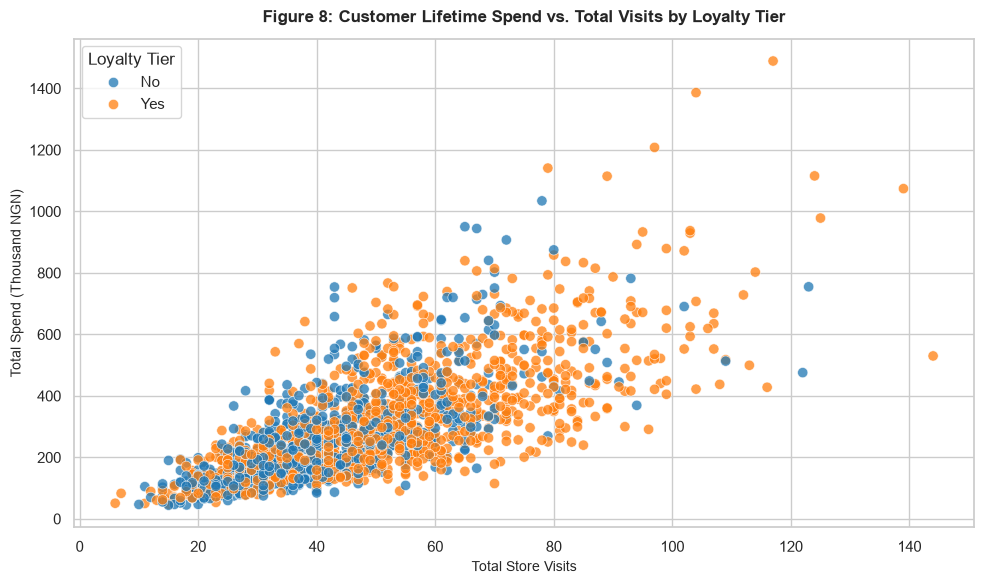

Figure 8 saved cleanly to figures/fig8_customer_spend_vs_visits.png


In [15]:
# -------------------------------------------------------------------------
# Figure 8: Customer Total Spend vs. Visits Coloured by Loyalty Tier
# -------------------------------------------------------------------------

# 1. Load the Customers sheet
excel_file = 'Brainpals_sales_analytics.xlsx'
customers = pd.read_excel(excel_file, sheet_name='Customers')

# Identify visit, spend, and tier column names dynamically
spend_col = [c for c in customers.columns if 'spend' in c][0]
visits_col = [c for c in customers.columns if 'visit' in c][0]
tier_col = [c for c in customers.columns if 'tier' in c or 'loyalty' in c][0]

# Standardise tier text formatting
customers[tier_col] = customers[tier_col].astype(str).str.strip().str.title()

# 2. Scale spend to thousands of NGN (k NGN)
customers['total_spend_k_ngn'] = customers[spend_col] / 1e3

# 3. Dynamically extract the actual unique tiers present in your data
actual_tiers = sorted(customers[tier_col].unique().tolist())
print(f"Detected Loyalty Tiers: {actual_tiers}")

# 4. Create the scatter plot using Seaborn
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=customers,
    x=visits_col,
    y='total_spend_k_ngn',
    hue=tier_col,
    hue_order=actual_tiers,       # Matches the exact detected labels
    palette='tab10',              # Distinct, high-contrast colours
    alpha=0.75,
    s=55,
    edgecolor='w',                # Crisp white outline around each marker
    linewidth=0.5,
    ax=ax
)

# 5. Position legend cleanly
sns.move_legend(ax, "upper left", title='Loyalty Tier', frameon=True)

# 6. Add titles and axis labels
plt.title('Figure 8: Customer Lifetime Spend vs. Total Visits by Loyalty Tier', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Total Store Visits', fontsize=10)
plt.ylabel('Total Spend (Thousand NGN)', fontsize=10)
plt.tight_layout()

# 7. Save figure at 300 DPI
plt.savefig('figures/fig8_customer_spend_vs_visits.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 8 saved cleanly to figures/fig8_customer_spend_vs_visits.png")